In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, RobustScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import optuna

import warnings
warnings.filterwarnings('ignore')

c:\Users\Louis Bernal\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Data Exploration

In [2]:
df = pd.read_csv('diabetes_dataset.csv')
df

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2018,Female,33.0,Wyoming,0,0,0,0,1,0,0,never,21.21,6.5,90,0
99996,2016,Female,80.0,Wyoming,0,1,0,0,0,0,0,No Info,36.66,5.7,100,0
99997,2018,Male,46.0,Wyoming,0,1,0,0,0,0,0,ever,36.12,6.2,158,0
99998,2018,Female,51.0,Wyoming,1,0,0,0,0,0,0,not current,29.29,6.0,155,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   year                  100000 non-null  int64  
 1   gender                100000 non-null  object 
 2   age                   100000 non-null  float64
 3   location              100000 non-null  object 
 4   race:AfricanAmerican  100000 non-null  int64  
 5   race:Asian            100000 non-null  int64  
 6   race:Caucasian        100000 non-null  int64  
 7   race:Hispanic         100000 non-null  int64  
 8   race:Other            100000 non-null  int64  
 9   hypertension          100000 non-null  int64  
 10  heart_disease         100000 non-null  int64  
 11  smoking_history       100000 non-null  object 
 12  bmi                   100000 non-null  float64
 13  hbA1c_level           100000 non-null  float64
 14  blood_glucose_level   100000 non-null  int64  
 15  d

In [4]:
df.describe()

,year,age,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,bmi,hbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,2018.360820,41.885856,0.202230,0.200150,0.198760,0.19888,0.199980,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,1.345239,22.516840,0.401665,0.400114,0.399069,0.39916,0.399987,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,2015.000000,0.080000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,2019.000000,24.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,2019.000000,43.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,2019.000000,60.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,2022.000000,80.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [5]:
# check outlier in string columns
for col in df.select_dtypes(['object']):
    print(f'\n', col , df[col].unique())



 gender ['Female' 'Male' 'Other']

 location ['Alabama' 'Alaska' 'Arizona' 'Arkansas' 'California' 'Colorado'
 'Connecticut' 'Delaware' 'District of Columbia' 'Florida' 'Georgia'
 'Guam' 'Hawaii' 'Idaho' 'Illinois' 'Indiana' 'Iowa' 'Kansas' 'Kentucky'
 'Louisiana' 'Maine' 'Maryland' 'Massachusetts' 'Michigan' 'Minnesota'
 'Mississippi' 'Missouri' 'Montana' 'Nebraska' 'Nevada' 'New Hampshire'
 'New Jersey' 'New Mexico' 'New York' 'North Carolina' 'North Dakota'
 'Ohio' 'Oklahoma' 'Oregon' 'Pennsylvania' 'Puerto Rico' 'Rhode Island'
 'South Carolina' 'South Dakota' 'Tennessee' 'Texas' 'United States'
 'Utah' 'Vermont' 'Virgin Islands' 'Virginia' 'Washington' 'West Virginia'
 'Wisconsin' 'Wyoming']

 smoking_history ['never' 'not current' 'current' 'No Info' 'ever' 'former']


In [6]:
df['diabetes'].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [7]:
df.isnull().sum()

year                    0
gender                  0
age                     0
location                0
race:AfricanAmerican    0
race:Asian              0
race:Caucasian          0
race:Hispanic           0
race:Other              0
hypertension            0
heart_disease           0
smoking_history         0
bmi                     0
hbA1c_level             0
blood_glucose_level     0
diabetes                0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(14)

#### Data Cleaning

In [9]:
df.drop_duplicates(inplace = True)

In [10]:
df.shape

(99986, 16)

#### EDA

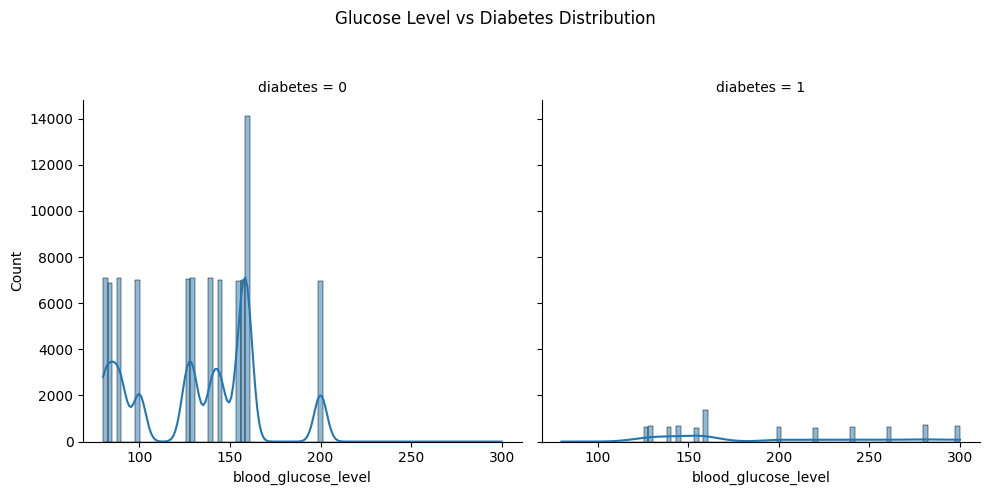

In [11]:
p = sns.displot(data=df, x = 'blood_glucose_level', col = 'diabetes', kde = True)
p.fig.suptitle('Glucose Level vs Diabetes Distribution')
p.fig.subplots_adjust(top = 0.80)

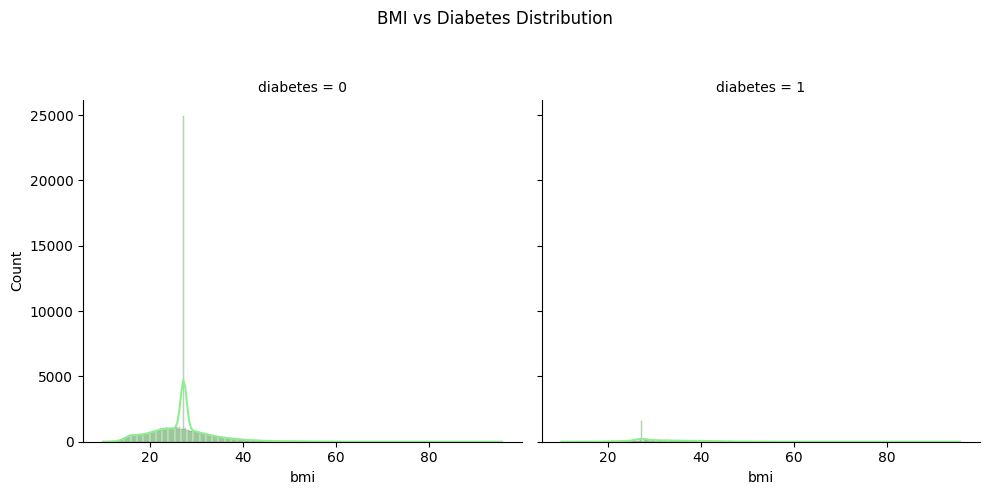

In [12]:
p = sns.displot(data=df, x = 'bmi', col = 'diabetes', kde = True, color = 'lightgreen')
p.fig.suptitle('BMI vs Diabetes Distribution')
p.fig.subplots_adjust(top = 0.80)

Text(0.5, 1.0, 'Blood Glucose Level ')

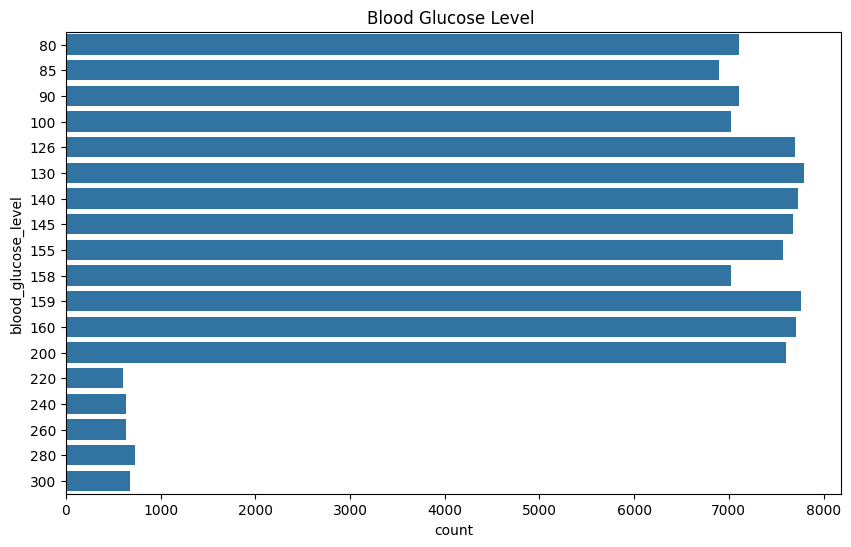

In [13]:
plt.figure(figsize=(10,6))
sns.countplot(data = df, y = 'blood_glucose_level')
plt.title('Blood Glucose Level ')

#### Outlier Detection

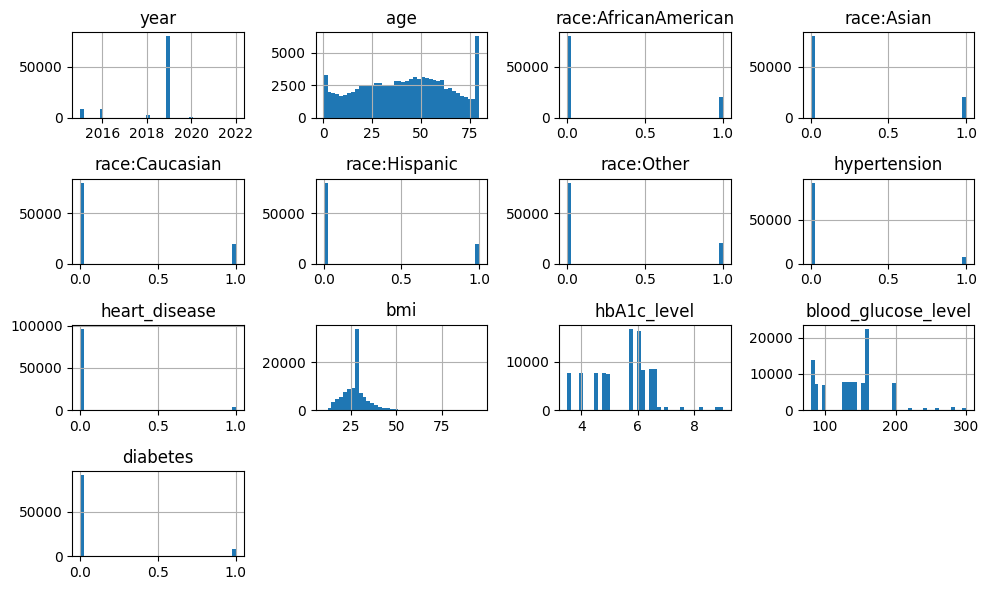

In [14]:
df.hist(figsize = (10, 6), bins = 40)
plt.tight_layout()

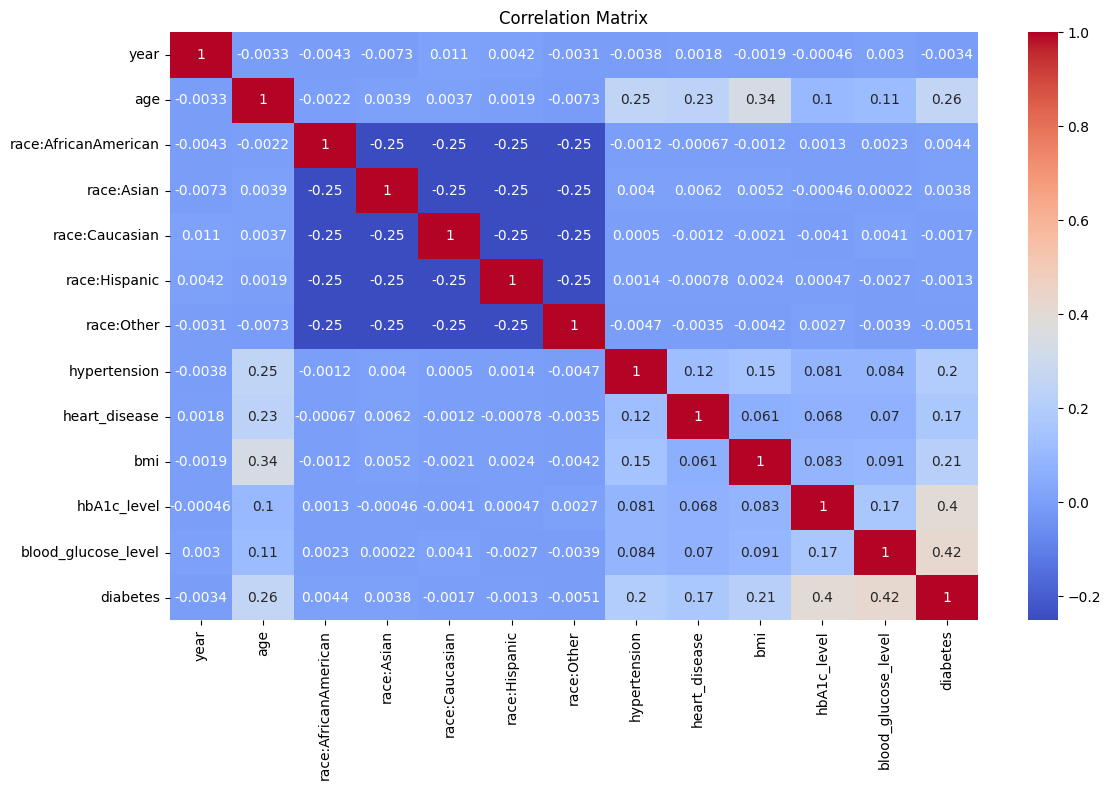

In [15]:
num_df = df.select_dtypes(exclude = 'object')
df_corr = num_df.corr()

plt.figure(figsize = (12, 8))
sns.heatmap(df_corr, annot= True, cmap = 'coolwarm')
plt.title('Correlation Matrix')
plt.tight_layout()

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
 [Text(0, 0, 'year'),
  Text(1, 0, 'age'),
  Text(2, 0, 'race:AfricanAmerican'),
  Text(3, 0, 'race:Asian'),
  Text(4, 0, 'race:Caucasian'),
  Text(5, 0, 'race:Hispanic'),
  Text(6, 0, 'race:Other'),
  Text(7, 0, 'hypertension'),
  Text(8, 0, 'heart_disease'),
  Text(9, 0, 'bmi'),
  Text(10, 0, 'hbA1c_level'),
  Text(11, 0, 'blood_glucose_level'),
  Text(12, 0, 'diabetes')])

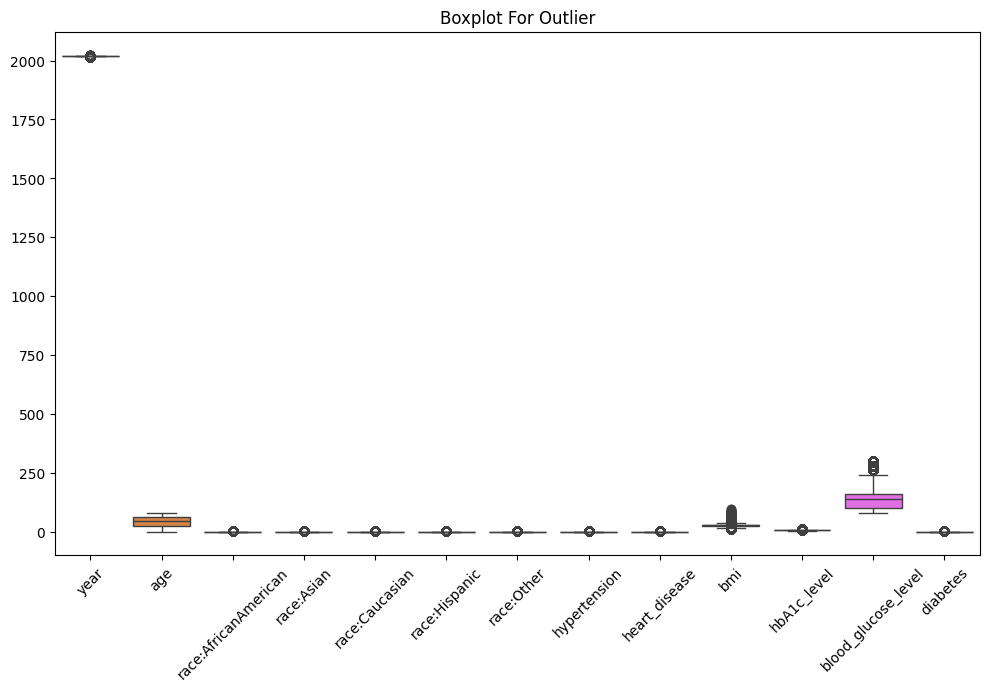

In [16]:
plt.figure(figsize = (10, 6))
sns.boxplot(data = df)
plt.title('Boxplot For Outlier')
plt.tight_layout()
plt.xticks(rotation = 45)

#### Data Preprocessing

In [18]:
df_object = df.select_dtypes(['object'])

for col in df_object:
    df[col] = LabelEncoder().fit_transform(df[col])

In [19]:
x = df.drop(['diabetes'], axis = 1)
y = df['diabetes']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)